# Lab 2: Generative and discriminative classification

Can simple Naive Bayes compete with logistic regression and a tree when they see the same information?

This is the restored **full six-part version**. The shortened Parts 1-3 notebook remains unchanged in `../lab2/`. Read [LAB2_EXPLAINED.md](LAB2_EXPLAINED.md) for the explanation.

Run top to bottom in the **lab2_2** folder with the **Python (lab2)** kernel. Read all eight reduced CSVs in `MachineLearningCVE/`; outputs go to `notebook_results/`. Existing scripts and outputs are untouched. This notebook has no hidden helper scripts, code comments, or progress prints. The complete representation has 49,757 columns because of one-hot ports; sparse storage saves memory, but full model training may still take a long time.

The full real-data run completed on 30 October 2026: all seven code cells, 18 model comparisons, 46 validation settings, and 21 inline figures. It read all eight CSVs: 2,830,743 raw rows; 2,522,362 after required duplicate removal; train/validation/test sizes 1,765,653 / 378,354 / 378,355. Every eligible row was used, except for the explicitly required 20% training experiment in Part 5. The successful run took about 35.4 minutes and passed independent checks in notebook_results/verification.json. This lab uses one multiclass-stratified random split, not Lab 1's three protocols.

Assignment: [downloaded Lab 2](Lab2.pdf). The completed [PDF report](output/pdf/report.pdf) has four main pages plus appendices; its editable LaTeX source is [report.tex](report.tex).


## Setup and fixed split

Read files in sorted order, then number their rows. Remove only copies with identical predictors **and** label. Keep and report conflicting-label vectors. Split 70/15/15 using the original multiclass labels, then derive binary labels: benign=0, attack=1. Save the row IDs and seed.

Use the same rows for every required binary comparison. Filenames and IDs never become predictors. This evaluates a similar mixture of flows, not new networks or future attack episodes.


In [1]:
%matplotlib inline
from pathlib import Path
import warnings, cloudpickle, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import sparse
from scipy.special import logsumexp
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import balanced_accuracy_score, classification_report, log_loss, ConfusionMatrixDisplay

SEED = 42
out = Path("notebook_results")
out.mkdir(exist_ok=True)


def save(table, name):
    display(table)
    table.to_csv(out / (name + ".csv"))


def figure(name):
    plt.tight_layout()
    plt.savefig(out / (name + ".png"), dpi=180)
    plt.show()
    plt.close()


files = sorted(Path("MachineLearningCVE").glob("*.csv"))
df = pd.concat([pd.read_csv(f).rename(columns=str.strip).assign(source_file=f.name) for f in files], ignore_index=True)
df.index.name = "row_id"
features = [c for c in df if c not in ["Label", "source_file"]]

raw, duplicate = len(df), df.duplicated(features + ["Label"])
df = df.loc[~duplicate].copy()
conflicts = df.loc[df.duplicated(features, keep=False), features + ["Label"]]
conflicts.to_csv(out / "conflicting_labels.csv")
assert df["Label"].notna().all()

train, rest = train_test_split(df.index, test_size=0.30, stratify=df["Label"], random_state=SEED)
val, test = train_test_split(rest, test_size=0.50, stratify=df.loc[rest, "Label"], random_state=SEED)
parts = [train, val, test]
for name, rows in zip(["train", "validation", "test"], parts):
    pd.Series(rows, name="row_id").to_csv(out / (name + "_ids.csv"), index=False)

save(pd.Series({"seed": SEED, "files": len(files), "raw_rows": raw, "removed_duplicates": int(duplicate.sum()),
                "conflicting_rows": len(conflicts), "train": len(train), 
                "validation": len(val), "test": len(test)}), "data_audit")
counts = pd.DataFrame({
    name: df.loc[rows, "Label"].value_counts()
    for name, rows in zip(["train", "validation", "test"], parts)
}).fillna(0).astype(int)
save(counts, "class_counts")

y = (df["Label"] != "BENIGN").astype(int)
x = df[features].replace([np.inf, -np.inf], np.nan)


seed                       42
files                       8
raw_rows              2830743
removed_duplicates     308381
conflicting_rows         1396
train                 1765653
validation             378354
test                   378355
dtype: int64

,train,validation,test
Label,,,
BENIGN,1467539,314472,314473
DoS Hulk,120994,25927,25928
DDoS,89611,19202,19203
PortScan,63573,13623,13623
DoS GoldenEye,7200,1543,1543
FTP-Patator,4153,890,890
DoS slowloris,3770,807,808
DoS Slowhttptest,3660,784,784
SSH-Patator,2253,483,483


## Part 1: Numerical diagnostics

Use **training rows only**, separately for benign and attack traffic. A feature is constant if it has at most one finite training value. Flag zero within-class variance, or a positive variance no larger than **10⁻⁶ times its overall training variance**. These flags justify checking variance smoothing, not deleting every low-variance measurement.

The compact table lists only problems. Remove training constants and the repeated `Fwd Header Length.1`; replace non-finite values using training medians later. Histograms use all finite training values with common bins for both classes. Signed log1p compresses extremes while preserving negative values for these plots; it is not a model transformation.


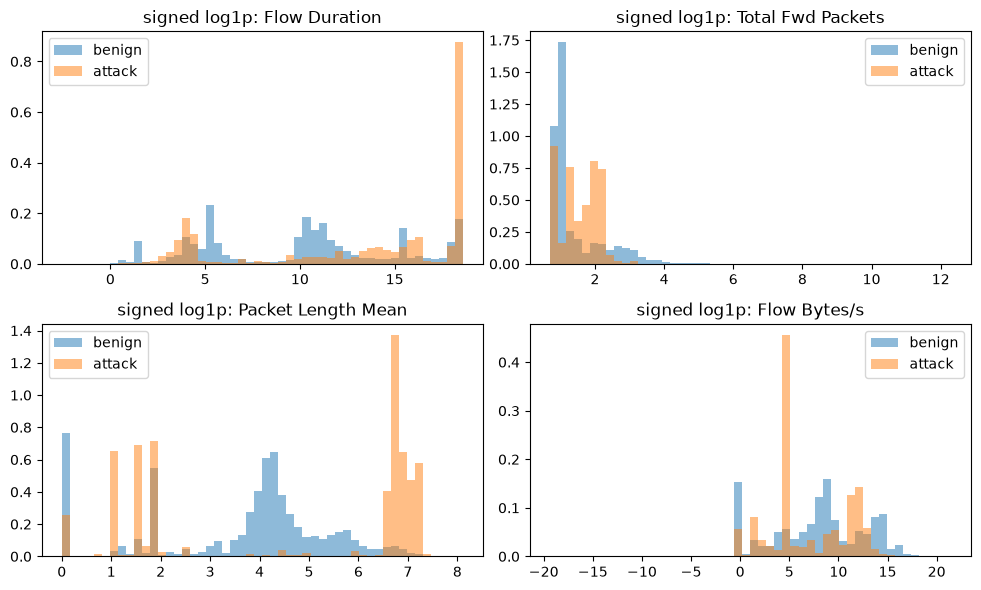

raw_skew      762.204503
log1p_skew     -0.160565
keep_log1p          True
dtype: object

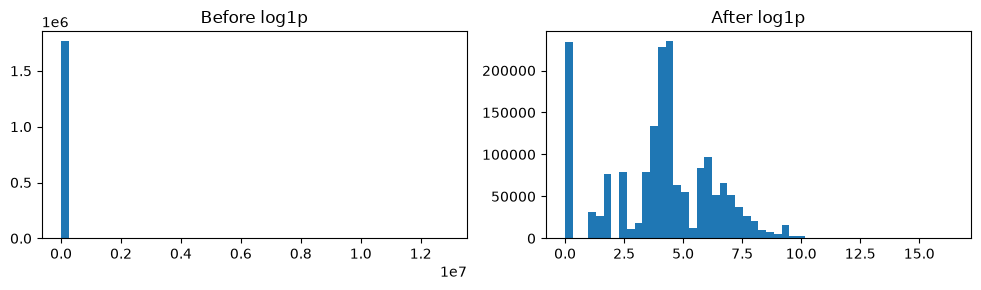

,feature,class,nonfinite,variance,small_variance,action
0,Flow Bytes/s,0,996,8.538266e+14,False,median impute; retain with smoothing check
1,Flow Bytes/s,1,98,1.793674e+13,False,median impute; retain with smoothing check
2,Flow Packets/s,0,996,4.781365e+10,False,median impute; retain with smoothing check
3,Flow Packets/s,1,98,6.931603e+09,False,median impute; retain with smoothing check
4,Bwd PSH Flags,0,0,0.000000e+00,True,remove
5,Bwd PSH Flags,1,0,0.000000e+00,True,remove
6,Fwd URG Flags,1,0,0.000000e+00,True,median impute; retain with smoothing check
7,Bwd URG Flags,0,0,0.000000e+00,True,remove
8,Bwd URG Flags,1,0,0.000000e+00,True,remove
9,Fwd Header Length,1,0,3.003922e+05,True,median impute; retain with smoothing check


In [2]:
numerical = [c for c in features if c != "Destination Port"]
constant = [c for c in numerical if x.loc[train, c].nunique() <= 1]
rows = []

for name in numerical:
    overall = x.loc[train, name].var(ddof=0)
    for label in [0, 1]:
        values = x.loc[train[y.loc[train] == label], name]
        variance = values.var(ddof=0)
        small = variance == 0 or (0 < variance <= 1e-6 * overall)
        bad = values.isna().sum()
        if bad or small or name in constant or name == "Fwd Header Length.1":
            action = (
                "remove" if name in constant + ["Fwd Header Length.1"]
                else "median impute; retain with smoothing check"
            )
            rows.append([name, label, bad, variance, small, action])

diagnostics = pd.DataFrame(rows, columns=["feature", "class", "nonfinite", "variance", "small_variance", "action"])
eligible = [c for c in numerical if c not in constant + ["Fwd Header Length.1"]]

fields = ["Flow Duration", "Total Fwd Packets", "Packet Length Mean", "Flow Bytes/s"]
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for name, ax in zip(fields, axes.flat):
    values = np.sign(x.loc[train, name]) * np.log1p(abs(x.loc[train, name]))
    bins = np.histogram_bin_edges(values.dropna(), bins=50)
    for label in [0, 1]:
        ax.hist(
            values.loc[y.loc[train] == label].dropna(), bins=bins,
            density=True, alpha=0.5, label=["benign", "attack"][label]
        )
    ax.set_title("signed log1p: " + name)
    ax.legend()
figure("training_histograms")

log_feature = "Total Length of Fwd Packets"
values = x.loc[train, log_feature].dropna()
assert values.min() >= 0
logged = np.log1p(values)
logs = [log_feature] if abs(logged.skew()) < abs(values.skew()) else []
save(pd.Series({"raw_skew": values.skew(), "log1p_skew": logged.skew(), "keep_log1p": bool(logs)}), "log_decision")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(values, bins=50)
axes[1].hist(logged, bins=50)
axes[0].set_title("Before log1p")
axes[1].set_title("After log1p")
figure("log_comparison")

if logs:
    diagnostics.loc[len(diagnostics)] = [log_feature, "both", 0, np.nan, False, "log1p: lower training skew"]
save(diagnostics, "numerical_attention")


## Part 2: Three representations

A: ten behavioral numerical features, excluding any training constants. B: destination port only. C: all eligible numerical features plus port. Counts and flags are numerical; a port is a service category.

`PortEncoder` learns training ports and reserves **-1 as “other”**, even though no training row needs it. Unknown or missing ports activate this one-hot column. Sparse encoding avoids a huge dense port matrix.

The hybrid model combines Gaussian numerical likelihoods with one categorical port likelihood. One-hot rows contain one count, so MultinomialNB gives exactly the smoothed categorical port probabilities, including “other”. Each library joint log probability already includes a prior: subtract the categorical model's prior to count it **once**, then normalize with log-sum-exp.

All imputation/scaling is learned from the relevant training rows. The log decision is made above using training data only. Trees reuse the standardized numerical inputs to keep preprocessing short; this changes their units, not the ordering of a feature.


In [3]:
class PortEncoder(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        self.ports_ = np.unique(values[np.isfinite(values)])
        assert (self.ports_ >= 0).all()
        self.encoder_ = OneHotEncoder(categories=[np.r_[-1, self.ports_]])
        self.encoder_.fit(self.ports_.reshape(-1, 1))
        return self

    def transform(self, X):
        values = np.asarray(X, dtype=float).copy()
        values[~np.isin(values, self.ports_)] = -1
        return self.encoder_.transform(values)

    def get_feature_names_out(self, input_features=None):
        return self.encoder_.get_feature_names_out(input_features)


class HybridNB(ClassifierMixin, BaseEstimator):
    def __init__(self, n_numeric, var_smoothing=1e-9, alpha=1):
        self.n_numeric, self.var_smoothing, self.alpha = n_numeric, var_smoothing, alpha

    def numeric(self, X):
        values = X[:, :self.n_numeric]
        return values.toarray() if sparse.issparse(values) else values

    def fit(self, X, y):
        self.g_ = GaussianNB(var_smoothing=self.var_smoothing).fit(self.numeric(X), y)
        self.c_ = MultinomialNB(alpha=self.alpha).fit(X[:, self.n_numeric:], y)
        self.classes_ = self.g_.classes_
        return self

    def predict_proba(self, X, prior=None):
        scores = self.g_.predict_joint_log_proba(self.numeric(X))
        scores += self.c_.predict_joint_log_proba(X[:, self.n_numeric:]) - self.c_.class_log_prior_
        if prior is not None:
            scores += np.log(prior) - np.log(self.g_.class_prior_)
        return np.exp(scores - logsumexp(scores, axis=1, keepdims=True))

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


subset = [c for c in ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
                      "Total Length of Fwd Packets", "Packet Length Mean", "Flow Packets/s", "Flow IAT Mean",
                      "SYN Flag Count", "ACK Flag Count", "Active Mean"] if c in eligible]
assert 6 <= len(subset) <= 12


def finite(X):
    return X.replace([np.inf, -np.inf], np.nan)


def prepare(columns, port, rows):
    blocks = []
    for name, cols in [
        ("numeric", [c for c in columns if c not in logs]),
        ("log", [c for c in columns if c in logs])
    ]:
        steps = [SimpleImputer(strategy="median", keep_empty_features=True)]
        if name == "log":
            steps.append(FunctionTransformer(np.log1p, feature_names_out="one-to-one"))
        blocks.append((name, make_pipeline(*steps, StandardScaler()), cols))

    if port:
        blocks.append(("port", PortEncoder(), ["Destination Port"]))

    prep = ColumnTransformer(blocks, sparse_threshold=1)
    arrays = [prep.fit_transform(x.loc[rows[0]])]
    arrays += [prep.transform(x.loc[r]) for r in rows[1:]]
    return prep, arrays


representations = {"numerical": (subset, False), "port": ([], True), "complete": (eligible, True)}


## Part 3: Binary models and validation

Naive Bayes uses empirical class priors learned from training. Predeclare Gaussian smoothing `[1e-9, 1e-7]` when the diagnostics flag tiny within-class variances, otherwise keep `1e-9`. Test categorical alpha `[1, 0.1, 10]`. Choose Naive Bayes settings by **validation log loss**.

Begin logistic regression without regularization (`C=np.inf`). If it does not converge or a coefficient exceeds 100 in absolute value, refit with L2 and C=1. The training log records the reason and whether the final fit converged. This rule never uses test scores.

Select tree depth from `[3,5,10,None]` by **validation balanced accuracy**, with None meaning unlimited. For each selected model, obtain test probabilities once and derive its predictions, scores, and confusion matrix from them. Saved tree rules show the first two split levels; numerical thresholds are in standardized units.

Log loss measures probability quality, not just correct labels. Very confident mistakes can make it large. [LogisticRegression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) explains unpenalized C; [MultinomialNB documentation](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html) describes smoothing and empirical priors.


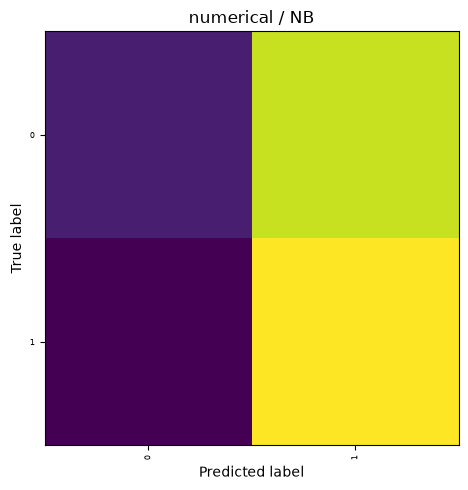

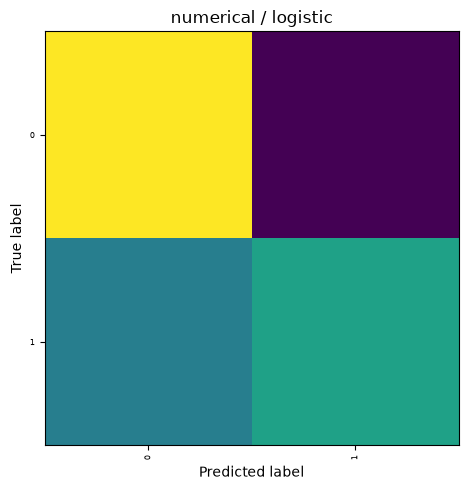

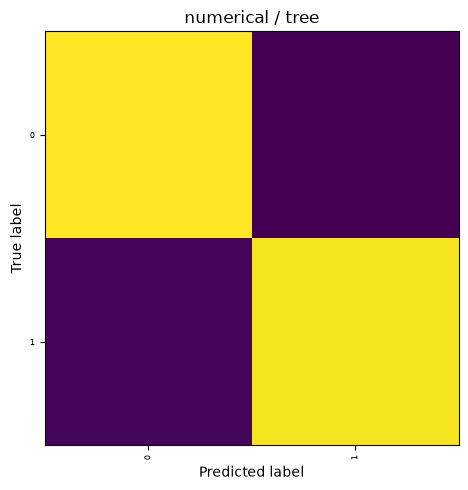

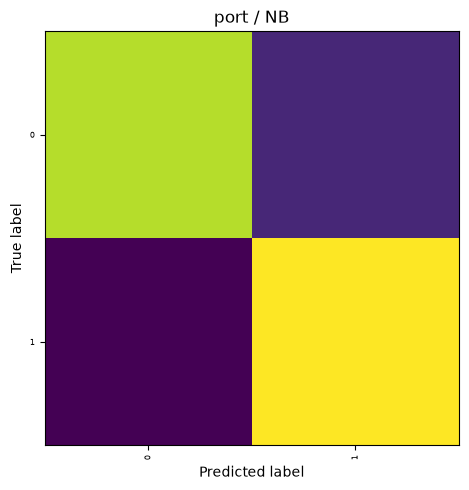

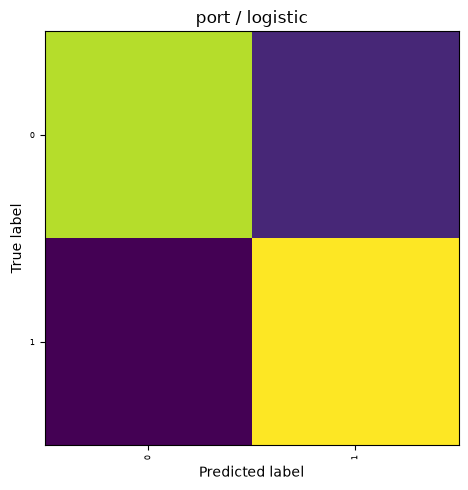

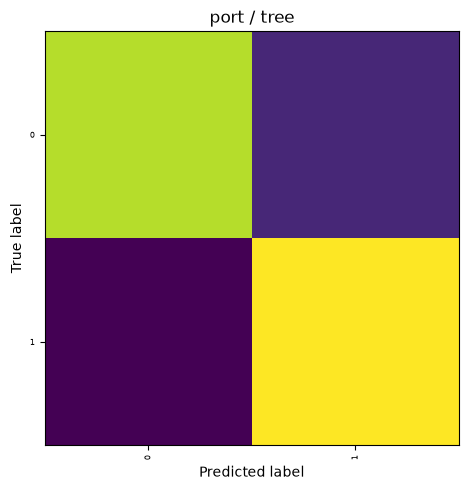

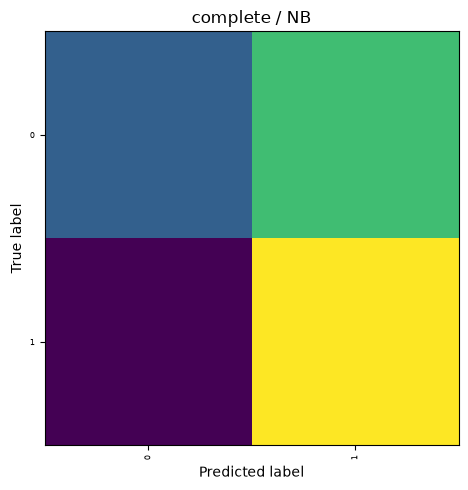

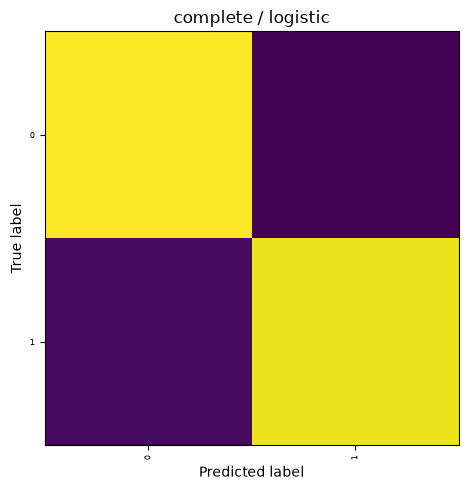

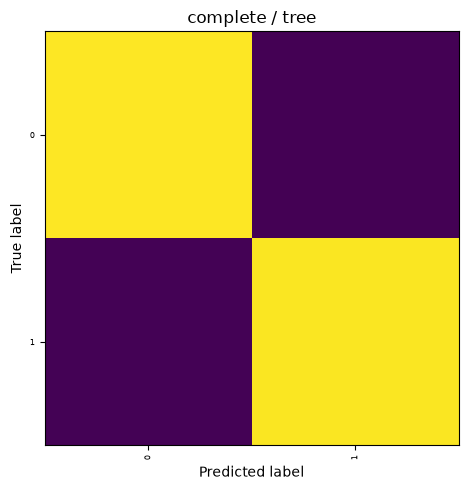

,experiment,model,setting,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss,macro_f1
0,numerical,NB,{'var_smoothing': 1e-09},0.539811,0.181012,0.984237,0.305787,4.710850,0.239719
1,numerical,logistic,{'C': inf},0.783427,0.952066,0.572712,0.715199,0.239561,0.835336
2,numerical,tree,{'max_depth': None},0.991345,0.988036,0.985113,0.986573,0.124762,0.991925
3,port,NB,{'alpha': 0.1},0.928577,0.614007,0.982640,0.755769,0.194898,0.843537
4,port,logistic,{'C': inf},0.928437,0.614070,0.982280,0.755710,0.189883,0.843512
5,port,tree,{'max_depth': None},0.928577,0.614007,0.982640,0.755769,0.196113,0.843537
6,complete,NB,"{'var_smoothing': 1e-07, 'alpha': 10}",0.649408,0.225650,0.986522,0.367289,17.681195,0.421125
7,complete,logistic,{'C': inf},0.961157,0.884606,0.947419,0.914936,0.066645,0.948456
8,complete,tree,{'max_depth': None},0.996890,0.995348,0.994725,0.995036,0.053498,0.997014


,representation,numerical_features,log1p_features,processing,dimension
0,numerical,"Flow Duration, Total Fwd Packets, Total Backwa...",Total Length of Fwd Packets,median + standardize; no port,10
1,port,,,one-hot port + other,49689
2,complete,"Flow Duration, Total Fwd Packets, Total Backwa...",Total Length of Fwd Packets,median + standardize; one-hot port + other,49757


In [4]:
results, tuning, recalls, dimensions, training_log, fit_times = [], [], [], [], [], []


def settings(model):
    return {k: getattr(model, k) for k in ["var_smoothing", "alpha", "C", "max_depth"] if hasattr(model, k)}


def fit_logistic(model, values, labels, experiment):
    for c in ([np.inf, 1] if np.isinf(model.C) else [model.C]):
        model.set_params(C=c)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(values, labels)
        failed = any(issubclass(w.category, ConvergenceWarning) for w in caught)
        maximum = abs(model.coef_).max()
        training_log.append([experiment, c, failed, maximum])
        if not failed and maximum <= 100:
            break
    return model


def compare(experiment, columns, port, rows, target, fixed=None):
    prep, (a, b, c) = prepare(columns, port, rows)
    truth = [target.loc[r] for r in rows]
    smoothing = [1e-9, 1e-7] if diagnostics.loc[diagnostics.feature.isin(columns), "small_variance"].any() else [1e-9]

    nb = HybridNB(len(columns)) if columns and port else MultinomialNB() if port else GaussianNB()
    grid = {"var_smoothing": smoothing} if columns else {}
    if port:
        grid["alpha"] = [1, 0.1, 10]
    models = {"NB": (nb, grid), "logistic": (LogisticRegression(C=np.inf, max_iter=1000, random_state=SEED), {}),
              "tree": (DecisionTreeClassifier(random_state=SEED), {"max_depth": [3, 5, 10, None]})}
    if fixed is not None:
        models = {name: (clone(pipe[-1]), {}) for name, pipe in fixed.items()}

    fitted = {}
    dimensions.append([experiment, ", ".join(columns), ", ".join([c for c in columns if c in logs]),
                       ("median + standardize; " if columns else "")
                       + ("one-hot port + other" if port else "no port"), a.shape[1]])

    for name, (estimator, grid) in models.items():
        best = -np.inf
        for params in ParameterGrid(grid):
            model = clone(estimator).set_params(**params)
            tick = time.perf_counter()
            model = fit_logistic(model, a, truth[0], experiment) if name == "logistic" else model.fit(a, truth[0])
            fit_times.append([experiment, name, str(settings(model)), time.perf_counter() - tick])
            pd.DataFrame(fit_times, columns=["experiment", "model", "setting", "fit_seconds"]).to_csv(out / "fit_times.csv", index=False)
            probability = model.predict_proba(b)
            balanced = balanced_accuracy_score(truth[1], model.classes_[probability.argmax(axis=1)])
            loss = log_loss(truth[1], probability, labels=model.classes_)
            tuning.append([experiment, name, str(settings(model)), balanced, loss])
            pd.DataFrame(tuning, columns=["experiment", "model", "settings", "validation_balanced_accuracy", "validation_log_loss"]).to_csv(out / "validation.csv", index=False)
            pd.Series({"experiment": experiment, "model": name, "settings": str(settings(model)), "validation_balanced_accuracy": balanced, "validation_log_loss": loss}).to_json(out / "latest_model.json")
            score = balanced if name == "tree" else -loss
            if score > best:
                best, chosen = score, model

        fitted[name] = Pipeline([("clean", FunctionTransformer(finite)), ("features", prep), ("classifier", chosen)])
        probability = chosen.predict_proba(c)
        prediction = chosen.classes_[probability.argmax(axis=1)]
        report = classification_report(truth[2], prediction, output_dict=True, zero_division=0)
        attack = report.get("1", {})
        setting = settings(chosen)
        results.append([experiment, name, str(setting), balanced_accuracy_score(truth[2], prediction),
                        attack.get("precision", np.nan), attack.get("recall", np.nan), attack.get("f1-score", np.nan),
                        log_loss(truth[2], probability, labels=chosen.classes_), report["macro avg"]["f1-score"]])
        recalls.extend([
            [experiment, name, label, report[str(label)]["recall"]]
            for label in sorted(set(truth[2]) | set(prediction))
        ])

        fig, ax = plt.subplots(figsize=(6, 5))
        ConfusionMatrixDisplay.from_predictions(
            truth[2], prediction, normalize="true", include_values=False,
            xticks_rotation=90, colorbar=False, ax=ax
        )
        ax.set_title(experiment + " / " + name)
        ax.tick_params(labelsize=6)
        figure(experiment.replace(" ", "_") + "_" + name + "_confusion")

        if name == "tree":
            sys.setrecursionlimit(max(sys.getrecursionlimit(), chosen.get_depth() + 100))
            _ = (out / (experiment.replace(" ", "_") + "_tree.txt")).write_text(
                export_text(chosen, feature_names=list(prep.get_feature_names_out()), max_depth=1)
            )

        if experiment == "complete" and name in ["logistic", "tree"]:
            with (out / (name + "_pipeline.pkl")).open("wb") as file:
                cloudpickle.dump(fitted[name], file)
            pd.DataFrame({"row_id": rows[2], "true": truth[2].to_numpy(), "predicted": prediction,
                          "attack_probability": probability[:, 1]}).to_csv(
                              out / (name + "_predictions.csv"), index=False
                          )

    return fitted


fitted = {name: compare(name, columns, port, parts, y) for name, (columns, port) in representations.items()}
metric_columns = [
    "experiment", "model", "setting", "balanced_accuracy", "attack_precision",
    "attack_recall", "attack_f1", "log_loss", "macro_f1"
]
save(pd.DataFrame(results, columns=metric_columns), "binary_results")
save(pd.DataFrame(dimensions, columns=["representation", "numerical_features", "log1p_features", "processing", "dimension"]),
     "representations")


The representation table counts one-hot port columns, including “other”. For port-only NB the probabilities are categorical despite the class name MultinomialNB. Compare NB, logistic, and tree **within a representation**, then ask whether adding features helped.

The complete logistic and tree pipelines and row-aligned predictions are saved for Lab 3. The pipelines also replace raw infinities, so a future caller does not need to clean them manually. Load trusted files with `cloudpickle.load`; custom class definitions are included in the serialized pipelines.


## Part 4: Check the assumptions

Use training data only. Correlations below use the transformed numerical representation, separately for benign and attack flows. White cells are undefined correlations for zero-variance features. A strong within-class correlation contradicts Naive Bayes' conditional-independence assumption.

The port tables show frequent and rare training services. An unseen port still gets positive NB probability through smoothing. For four training examples, positive log-odds contributions favor attack and negative ones favor benign. Show two correct and two wrong predictions where available, the largest numerical contributions, port, and the prior.


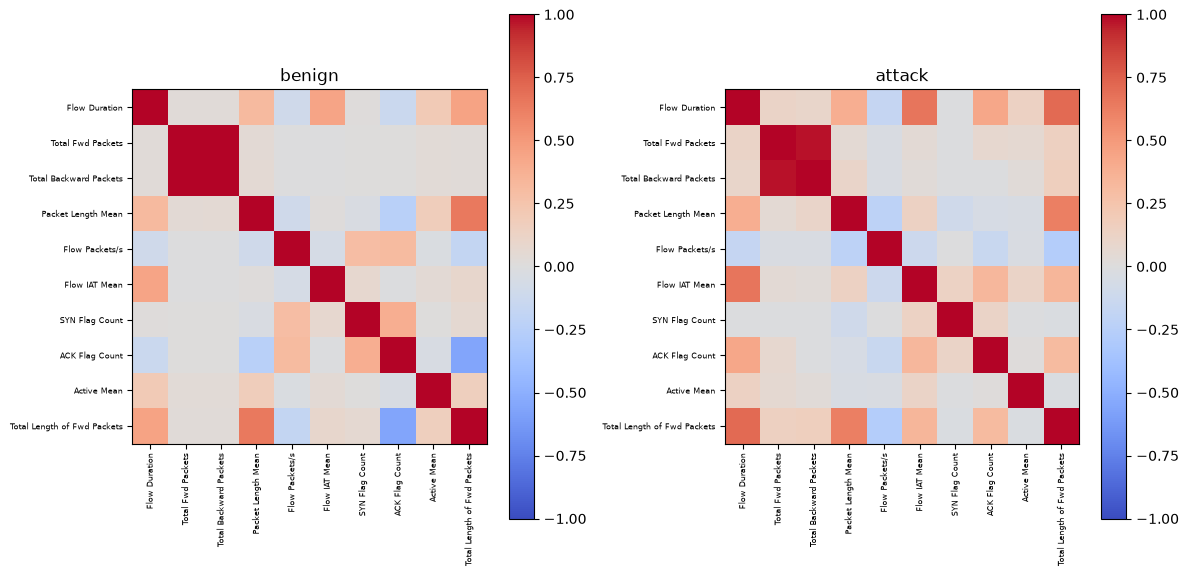

,class,absolute_correlation,feature1,feature2
0,0,0.999102,Total Backward Packets,Total Fwd Packets
1,1,0.976358,Total Backward Packets,Total Fwd Packets


Label,0,1
Destination Port,,
53,614017,70
80,152700,226982
443,329035,105
123,14963,1
22,4773,2430
21,2386,4314
389,4119,58
88,3574,50
137,2098,0


Label,0,1
Destination Port,,
1101,3,0
1103,4,0
1109,1,0
1115,5,0
1116,4,0
1118,2,0
1120,2,0
1125,2,0
1127,5,0


rare_ports_total_count_at_most_5    31135
other_training_count                    0
dtype: int64

,row_id,true,predicted,feature,log_odds_contribution
0,2731351,0,0,numeric__URG Flag Count,-96.418340
1,2731351,0,0,numeric__ECE Flag Count,8.151651
2,2731351,0,0,numeric__RST Flag Count,8.151650
3,2731351,0,0,Destination Port,0.809300
4,2731351,0,0,prior,-1.593866
5,2672184,0,0,numeric__URG Flag Count,-96.418340
6,2672184,0,0,numeric__Init_Win_bytes_backward,-16.559335
7,2672184,0,0,numeric__Flow Packets/s,-13.818320
8,2672184,0,0,Destination Port,0.029141
9,2672184,0,0,prior,-1.593866


In [5]:
values = fitted["numerical"]["NB"][:-1].transform(x.loc[train])
names = [name.split("__", 1)[1] for name in fitted["numerical"]["NB"].named_steps["features"].get_feature_names_out()]
values = pd.DataFrame(values, index=train, columns=names)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
pairs = []
for label, ax in zip([0, 1], axes):
    corr = values.loc[y.loc[train] == label].corr()
    image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(names)), names, rotation=90, fontsize=6)
    ax.set_yticks(range(len(names)), names, fontsize=6)
    ax.set_title(["benign", "attack"][label])
    strongest = max(
        (abs(corr.iloc[i, j]), names[i], names[j])
        for i in range(len(names)) for j in range(i) if pd.notna(corr.iloc[i, j])
    )
    pairs.append([label, *strongest])
    fig.colorbar(image, ax=ax)
figure("within_class_correlation")
save(pd.DataFrame(pairs, columns=["class", "absolute_correlation", "feature1", "feature2"]), "dependence")

ports = pd.crosstab(df.loc[train, "Destination Port"], y.loc[train])
save(ports.loc[ports.sum(axis=1).nlargest(10).index], "frequent_ports")
rare = ports[ports.sum(axis=1) <= 5]
save(rare.head(10), "rare_port_examples")
save(pd.Series({"rare_ports_total_count_at_most_5": len(rare), "other_training_count": 0}), "rare_ports")

pipe = fitted["complete"]["NB"]
prediction = pipe.predict(x.loc[train])
examples = list(train[prediction == y.loc[train]][:2]) + list(train[prediction != y.loc[train]][:2])
contributions = []
for row in examples:
    transformed = pipe[:-1].transform(x.loc[[row]])
    model = pipe[-1]
    z = model.numeric(transformed)[0]
    g = model.g_
    numeric = -0.5 * (
        np.log(g.var_[1] / g.var_[0])
        + (z - g.theta_[1])**2 / g.var_[1]
        - (z - g.theta_[0])**2 / g.var_[0]
    )
    effect = pd.Series(numeric, index=pipe.named_steps["features"].get_feature_names_out()[:len(eligible)])
    effect = effect.loc[effect.abs().nlargest(3).index]
    effect["Destination Port"] = float(np.asarray(
        transformed[:, len(eligible):]
        @ (model.c_.feature_log_prob_[1] - model.c_.feature_log_prob_[0])
    ).ravel()[0])
    effect["prior"] = np.log(g.class_prior_[1] / g.class_prior_[0])
    contributions.extend([
        [row, int(y.loc[row]), int(pipe.predict(x.loc[[row]])[0]), feature, value]
        for feature, value in effect.items()
    ])

save(pd.DataFrame(contributions, columns=["row_id", "true", "predicted", "feature", "log_odds_contribution"]),
     "hybrid_examples")


Even the complete model ignores dependence between packet totals and their subflow versions, and between service port and traffic behavior. Adding correlated likelihoods can make NB too confident. Relate the correlation and example tables to measured F1 and log loss, rather than assuming more features must help.

If fewer than two errors exist in training, the example table contains the available errors instead of inventing incorrect predictions.


## Part 5: Less training data and a different prior

This **required** experiment keeps 20% of benign and 20% of attack training rows, using binary-stratified sampling and seed 42. Validation and test IDs stay fixed. Refit preprocessing and the selected complete-model settings; do not retune the tree depth. Compare the change in attack F1 and recall; the change table is sorted with the largest F1 drop first.

Then return to the full fitted models. Choose five test flows nearest probability 0.5 per model, without using their labels. Change the assumed deployment prevalence to 5%. Hybrid NB replaces its prior while keeping both likelihood models fixed; logistic and tree use the supplied posterior correction. This is a what-if probability calculation, not a new evaluation on data actually drawn at 5% prevalence.


,full,20_percent
Label,,
0,1467539,293507
1,298114,59623


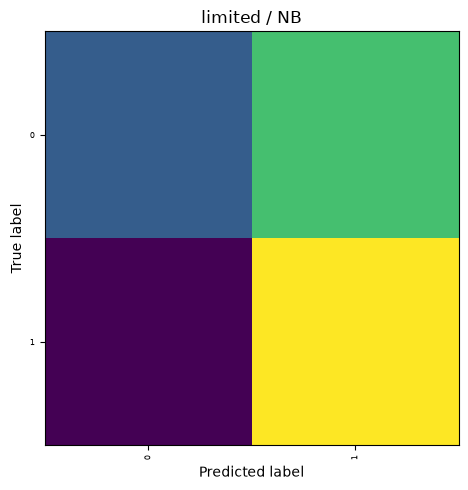

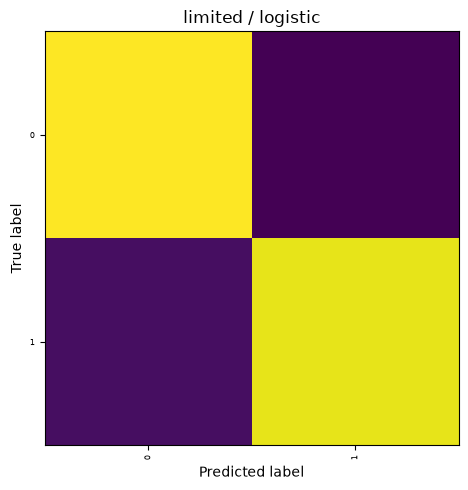

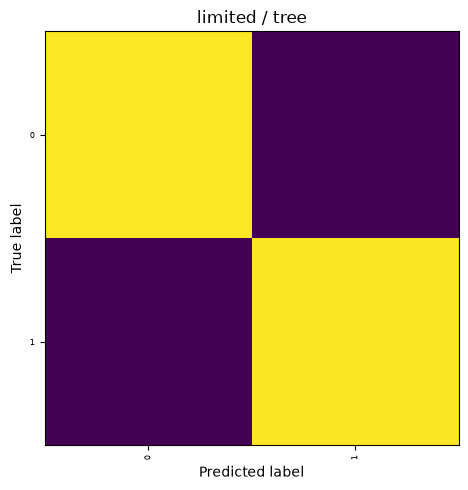

,attack_f1,attack_recall
model,,
NB,-0.004138,-0.000266
tree,-0.000982,-0.000250
logistic,0.001733,-0.004383


,model,row_id,training_prior,deployment_prior,before,after
0,NB,1840101,0.168841,0.05,0.499814,0.205655
1,NB,551062,0.168841,0.05,0.500394,0.206034
2,NB,1485611,0.168841,0.05,0.499550,0.205483
3,NB,2503681,0.168841,0.05,0.499547,0.205481
4,NB,647757,0.168841,0.05,0.499543,0.205478
5,logistic,706357,0.168841,0.05,0.499997,0.205775
6,logistic,247393,0.168841,0.05,0.500005,0.205780
7,logistic,1666009,0.168841,0.05,0.500005,0.205780
8,logistic,1829509,0.168841,0.05,0.500009,0.205783
9,logistic,745603,0.168841,0.05,0.499971,0.205758


In [6]:
small, _ = train_test_split(train, train_size=0.20, stratify=y.loc[train], random_state=SEED)
pd.Series(small, name="row_id").to_csv(out / "small_training_ids.csv", index=False)
save(pd.DataFrame({"full": y.loc[train].value_counts(), "20_percent": y.loc[small].value_counts()}), "limited_counts")

limited = compare("limited", eligible, True, [small, val, test], y, fixed=fitted["complete"])
table = pd.DataFrame(results, columns=metric_columns)
change = (
    table[table.experiment == "limited"].set_index("model")[["attack_f1", "attack_recall"]]
    - table[table.experiment == "complete"].set_index("model")[["attack_f1", "attack_recall"]]
)
save(change.sort_values("attack_f1"), "limited_change")

prior = float(y.loc[train].mean())
deployment = 0.05
shift = []

for name, pipe in fitted["complete"].items():
    probability = pipe.predict_proba(x.loc[test])[:, 1]
    nearest = np.argsort(abs(probability - 0.5))[:5]
    rows = test[nearest]
    before = probability[nearest]
    if name == "NB":
        after = pipe[-1].predict_proba(pipe[:-1].transform(x.loc[rows]), prior=[1 - deployment, deployment])[:, 1]
    else:
        after = (deployment / prior) * before / (
            (deployment / prior) * before
            + ((1 - deployment) / (1 - prior)) * (1 - before)
        )
    shift.extend([[name, row, prior, deployment, a, b] for row, a, b in zip(rows, before, after)])

save(pd.DataFrame(shift, columns=["model", "row_id", "training_prior", "deployment_prior", "before", "after"]),
     "prior_shift")


A new prior changes how common attacks are assumed to be, while keeping within-class traffic distributions fixed. A cost-based threshold instead changes the action taken for a given probability because missed attacks and false alarms have different costs. They can be used together, but are not the same operation.

Posterior correction assumes reliable training probabilities. NB's independence violations and a tree's coarse leaf probabilities can weaken that assumption. Equal tree probabilities can mean the five “nearest” flows share one leaf rather than lying very close to 0.5.


## Part 6: Multiclass and the effect of port

Keep benign plus only attacks with at least **100 train, 20 validation, and 20 test rows**. List excluded attack labels; they remain in **every binary experiment** above. Filter the original partitions, do not make another random split.

Compare the same eligible behavioral features without port (GaussianNB) and with categorical port (hybrid NB), along with logistic and a tree. Use the same smoothing/depth rules and validation criteria. Report macro F1, class-wise recall, and confusion matrices. A port-related gain may identify the targeted service or simply CICIDS2017's fixed attack setup.


,train,validation,test
Label,,,
Infiltration,25,6,5
Web Attack � Sql Injection,15,3,3
Heartbleed,8,2,1


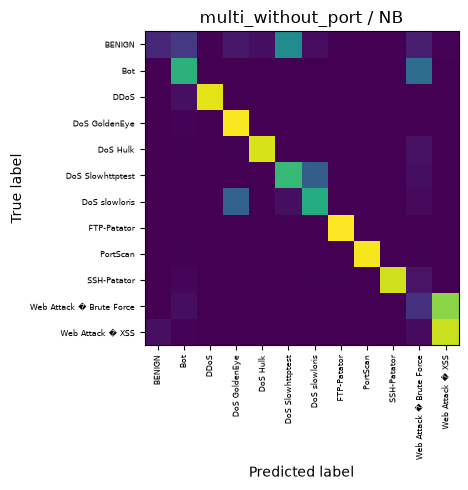

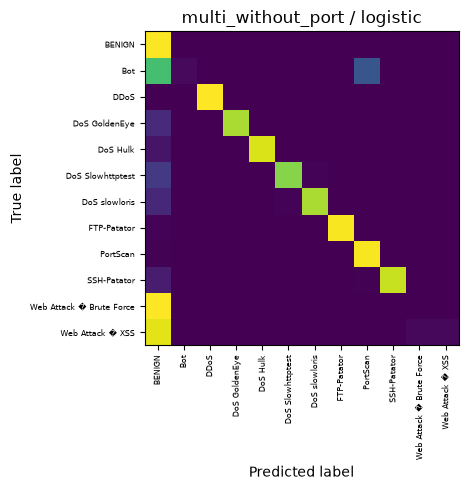

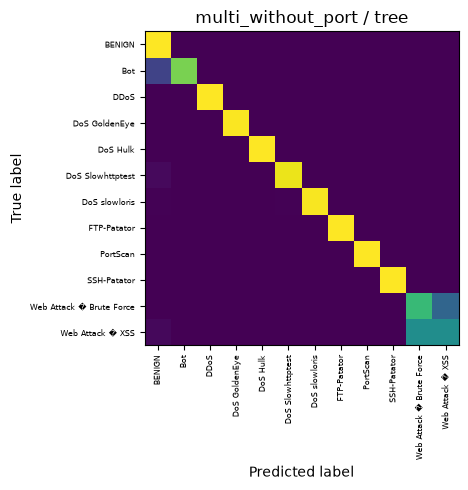

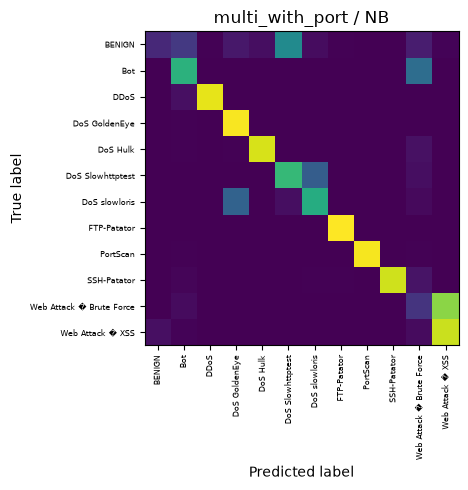

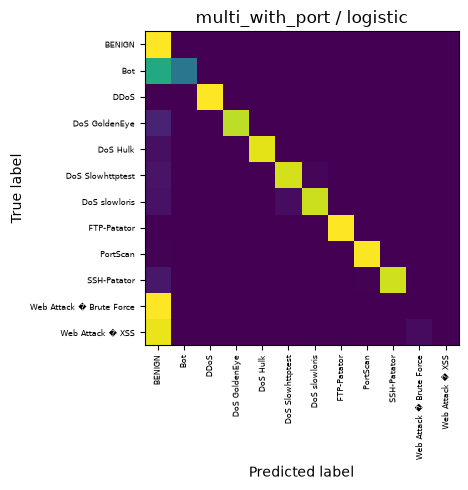

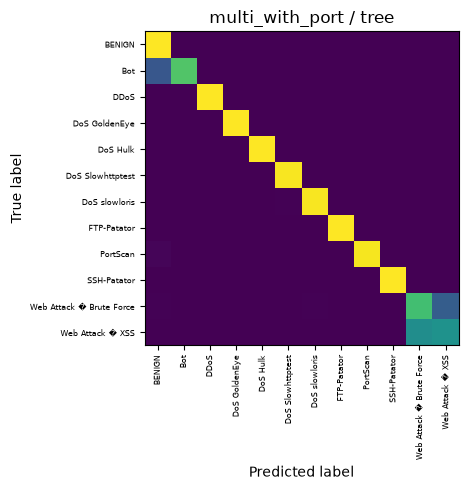

,experiment,model,setting,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss,macro_f1
0,numerical,NB,{'var_smoothing': 1e-09},0.539811,0.181012,0.984237,0.305787,4.710850,0.239719
1,numerical,logistic,{'C': inf},0.783427,0.952066,0.572712,0.715199,0.239561,0.835336
2,numerical,tree,{'max_depth': None},0.991345,0.988036,0.985113,0.986573,0.124762,0.991925
3,port,NB,{'alpha': 0.1},0.928577,0.614007,0.982640,0.755769,0.194898,0.843537
4,port,logistic,{'C': inf},0.928437,0.614070,0.982280,0.755710,0.189883,0.843512
5,port,tree,{'max_depth': None},0.928577,0.614007,0.982640,0.755769,0.196113,0.843537
6,complete,NB,"{'var_smoothing': 1e-07, 'alpha': 10}",0.649408,0.225650,0.986522,0.367289,17.681195,0.421125
7,complete,logistic,{'C': inf},0.961157,0.884606,0.947419,0.914936,0.066645,0.948456
8,complete,tree,{'max_depth': None},0.996890,0.995348,0.994725,0.995036,0.053498,0.997014
9,limited,NB,"{'var_smoothing': 1e-07, 'alpha': 10}",0.643179,0.222548,0.986256,0.363151,17.553767,0.411911


,experiment,model,class,recall
0,numerical,NB,0,0.095385
1,numerical,NB,1,0.984237
2,numerical,logistic,0,0.994143
3,numerical,logistic,1,0.572712
4,numerical,tree,0,0.997577
...,...,...,...,...
91,multi_with_port,tree,FTP-Patator,0.997753
92,multi_with_port,tree,PortScan,0.984805
93,multi_with_port,tree,SSH-Patator,0.997930
94,multi_with_port,tree,Web Attack � Brute Force,0.695455


experiment                         multi_with_port  multi_without_port  \
model    class                                                           
logistic Bot                              0.392491            0.027304   
         DoS Slowhttptest                 0.933673            0.817602   
         DoS slowloris                    0.918317            0.873762   
         DoS GoldenEye                    0.900843            0.874919   
tree     Web Attack � Brute Force         0.695455            0.672727   
         DoS Slowhttptest                 0.991071            0.969388   
         Web Attack � XSS                 0.510204            0.489796   
logistic SSH-Patator                      0.929607            0.915114   
         DoS Hulk                         0.958655            0.944732   
NB       Web Attack � Brute Force         0.150000            0.140909   
logistic FTP-Patator                      0.996629            0.992135   
         BENIGN                           0.998658            0.995745   
NB       BENIGN                           0.114379            0.111599   
         DDoS                             0.958913            0.956205   
tree     DoS GoldenEye                    0.996111            0.994167   
         DoS slowloris                    0.990099            0.988861   
         FTP-Patator                      0.997753            0.996629   
NB       DoS Hulk                         0.937211            0.936285   
logistic PortScan                         0.992366            0.991999   
         DDoS                             0.998906            0.998594   
tree     DoS Hulk                         0.997917            0.997609   
         DDoS                             0.999896            0.999635   
         BENIGN                           0.999122            0.999043   
         SSH-Patator                      0.997930            0.997930   
NB       DoS GoldenEye                    0.988334            0.988334   
         DoS slowloris                    0.617574            0.617574   
logistic Web Attack � Brute Force         0.000000            0.000000   
NB       PortScan                         0.982603            0.982603   
         SSH-Patator                      0.923395            0.923395   
         Bot                              0.641638            0.641638   
         Web Attack � XSS                 0.918367            0.918367   
         DoS Slowhttptest                 0.665816            0.665816   
         FTP-Patator                      0.996629            0.996629   
tree     PortScan                         0.984805            0.999193   
logistic Web Attack � XSS                 0.000000            0.020408   
tree     Bot                              0.726962            0.798635   

experiment                         port_gain  
model    class                                
logistic Bot                        0.365188  
         DoS Slowhttptest           0.116071  
         DoS slowloris              0.044554  
         DoS GoldenEye              0.025924  
tree     Web Attack � Brute Force   0.022727  
         DoS Slowhttptest           0.021684  
         Web Attack � XSS           0.020408  
logistic SSH-Patator                0.014493  
         DoS Hulk                   0.013923  
NB       Web Attack � Brute Force   0.009091  
logistic FTP-Patator                0.004494  
         BENIGN                     0.002913  
NB       BENIGN                     0.002779  
         DDoS                       0.002708  
tree     DoS GoldenEye              0.001944  
         DoS slowloris              0.001238  
         FTP-Patator                0.001124  
NB       DoS Hulk                   0.000926  
logistic PortScan                   0.000367  
         DDoS                       0.000312  
tree     DoS Hulk                   0.000309  
         DDoS                       0.000260  
         BENIGN                     0.000079  
         SSH

,experiment,model,settings,validation_balanced_accuracy,validation_log_loss
0,numerical,NB,{'var_smoothing': 1e-09},0.540340,4.711261
1,numerical,logistic,{'C': inf},0.782893,0.240247
2,numerical,tree,{'max_depth': 3},0.839330,0.172935
3,numerical,tree,{'max_depth': 5},0.962576,0.066174
4,numerical,tree,{'max_depth': 10},0.987338,0.025400
5,numerical,tree,{'max_depth': None},0.991538,0.120270
6,port,NB,{'alpha': 1},0.928837,0.208148
7,port,NB,{'alpha': 0.1},0.929077,0.194341
8,port,NB,{'alpha': 10},0.527967,0.243155
9,port,logistic,{'C': inf},0.928924,0.189283


,experiment,C,convergence_warning,max_abs_coefficient
0,numerical,inf,False,49.358546
1,port,inf,False,43.170478
2,complete,inf,False,77.364627
3,limited,inf,False,80.792701
4,multi_without_port,inf,False,90.751224
5,multi_with_port,inf,False,31.385511


,representation,numerical_features,log1p_features,processing,dimension
0,numerical,"Flow Duration, Total Fwd Packets, Total Backwa...",Total Length of Fwd Packets,median + standardize; no port,10
1,port,,,one-hot port + other,49689
2,complete,"Flow Duration, Total Fwd Packets, Total Backwa...",Total Length of Fwd Packets,median + standardize; one-hot port + other,49757
3,limited,"Flow Duration, Total Fwd Packets, Total Backwa...",Total Length of Fwd Packets,median + standardize; one-hot port + other,28565
4,multi_without_port,"Flow Duration, Total Fwd Packets, Total Backwa...",Total Length of Fwd Packets,median + standardize; no port,68
5,multi_with_port,"Flow Duration, Total Fwd Packets, Total Backwa...",Total Length of Fwd Packets,median + standardize; one-hot port + other,49757


In [7]:
keep = counts.index[(counts["train"] >= 100) & (counts["validation"] >= 20) & (counts["test"] >= 20)].tolist()
if "BENIGN" not in keep:
    keep.append("BENIGN")
save(counts.loc[~counts.index.isin(keep)], "excluded_multiclass")

multi_parts = [rows[df.loc[rows, "Label"].isin(keep)] for rows in parts]
multi = {
    name: compare(name, eligible, port, multi_parts, df["Label"])
    for name, port in [("multi_without_port", False), ("multi_with_port", True)]
}
save(pd.DataFrame(results, columns=metric_columns), "all_results")

recall = pd.DataFrame(recalls, columns=["experiment", "model", "class", "recall"])
save(recall, "class_recall")

effect = recall[recall.experiment.str.startswith("multi")].pivot(
    index=["model", "class"], columns="experiment", values="recall"
)
effect["port_gain"] = effect["multi_with_port"] - effect["multi_without_port"]
save(effect.sort_values("port_gain", ascending=False), "port_effect")

save(pd.DataFrame(tuning, columns=["experiment", "model", "settings", "validation_balanced_accuracy", "validation_log_loss"]),
     "validation")
save(pd.DataFrame(training_log, columns=["experiment", "C", "convergence_warning", "max_abs_coefficient"]),
     "logistic_training")
save(pd.DataFrame(dimensions, columns=["representation", "numerical_features", "log1p_features", "processing", "dimension"]),
     "all_dimensions")


## Discussion: measured full-data findings

1. **The strongest binary NB variant was port-only.** Its test attack F1 was 0.7558, compared with 0.7557 for port-only logistic regression and 0.7558 for the port-only tree. Its log loss was 0.1949, slightly worse than logistic's 0.1899. This categorical model was competitive when all models saw only the service identifier. With complete features, the tree was much stronger: attack F1 0.9950 versus 0.9149 for logistic regression and 0.3673 for hybrid NB.

2. **More features did not make NB reliable.** Numerical Gaussian NB had attack F1 0.3058 and log loss 4.7108. Hybrid NB improved F1 to 0.3673 but worsened log loss to 17.6812. Hybrid recall was high (0.9865), but precision was only 0.2257: many predicted attacks were false alarms. Its very large log loss shows that some mistakes were extremely confident. This is an observed limitation, not a reason to hide the results or change the frozen smoothing grid after testing.

3. **Training evidence challenges NB's assumptions.** Forward/backward packet totals had within-class correlations of 0.9991 for benign and 0.9764 for attack traffic. These related measurements are not separate independent pieces of evidence. Training histograms and small-variance flags also warn against a simple Gaussian description of every feature. Lowering one feature's skew with log1p does not establish Gaussianity within every class. The saved four-example table separates numerical, port, and prior contributions; it does not prove a causal attack mechanism.

4. **The required 20% experiment affected metrics differently.** Hybrid NB had the largest attack-F1 drop, about 0.00414; the tree dropped about 0.00098. Logistic F1 increased slightly, about 0.00173, while its recall fell about 0.00438, the largest recall decrease. Therefore there is no single most-affected model across every metric. These are one fixed reduced-training experiment, not repeated-sampling confidence estimates.

5. **The explicit prior permits a direct prevalence adjustment.** Hybrid NB can replace its class prior while keeping learned feature likelihoods fixed. Logistic regression and the tree use the supplied posterior correction. Assuming 5% attacks lowers non-extreme attack probabilities, but this is a what-if calculation, not performance measured on a newly collected 5%-attack dataset. A cost-based threshold controls alert decisions instead. Prior adjustment does not repair poorly calibrated probabilities or invalid class-conditional assumptions.

6. **Port helped multiclass logistic regression most clearly.** Macro-F1 increased from 0.7171 without port to 0.7716 with port. Bot recall rose from 0.0273 to 0.3925, and DoS Slowhttptest recall from 0.8176 to 0.9337. The tree changed little in macro-F1 (0.9050 to 0.9066), while NB decreased slightly (0.3492 to 0.3435). Service information is useful in some models, but its gain may reflect CICIDS2017's scheduled attack/service combinations.

All results concern this fixed random-split CICIDS2017 mixture. They do not establish production readiness, zero-day detection, or generalization to a new network, organization, or attack execution. Every logistic fit converged under the declared rule without needing the L2 fallback; that is specific to this run, not a universal property of unregularized fitting.

### Submission checklist

The notebook writes split IDs and counts, the attention and representation tables, training-only plots, all validation settings, test results and confusions, first-two-level tree rules, limited-data changes, prior-shift examples, and multiclass port effects. Complete binary logistic/tree pipelines and predictions are saved for Lab 3. The standalone written report is not created by this notebook.

The tables and figures above are measured full-data results. The separate [PDF report](output/pdf/report.pdf) uses notebook_results/all_results.csv, validation.csv, and verification.json. Its builder reads saved results without repeating model training.
